# Credit card fraud detection

The dataset is about 285,000 card transactions made by European cardholders over two days in September 2013. Only a tiny fraction of them are fraud.
Features `V1` to `V28` are PCA components (the original features were hidden for privacy), plus `Time`, `Amount` and the label `Class` (1 = fraud).

In [1]:
# import packages (tensorflow first, importing it after pandas made training hang on my Mac)
import tensorflow as tf
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             average_precision_score, precision_recall_curve, confusion_matrix)

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# seeds so the results can be repeated
SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [3]:
# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

df = pd.read_csv(path + "/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())

Shape: (284807, 31)
Missing values: 0


In [5]:
counts = df['Class'].value_counts()
print(counts)
print("Fraud percentage:", round(counts[1] / len(df) * 100, 3), "%")

Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.173 %


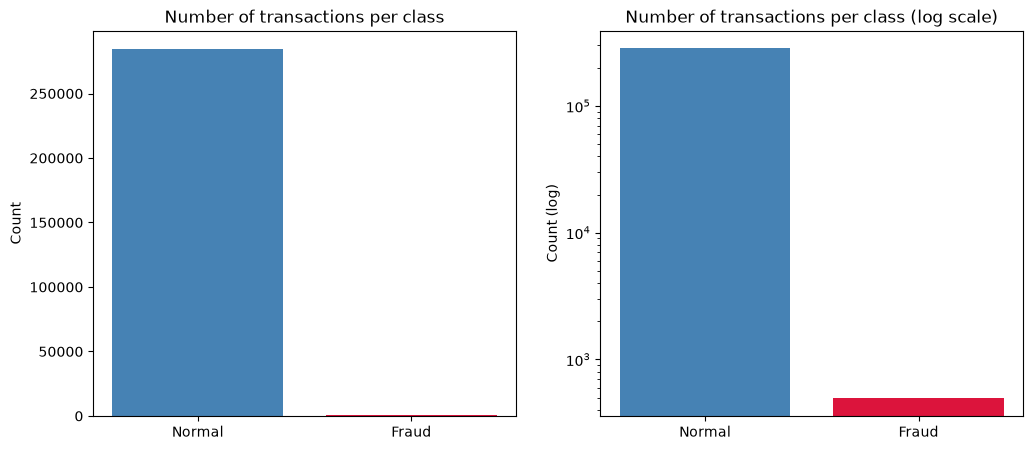

In [6]:
# plot the class imbalance, normal scale and log scale
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Normal', 'Fraud'], counts.values, color=['steelblue', 'crimson'])
axes[0].set_title('Number of transactions per class')
axes[0].set_ylabel('Count')

axes[1].bar(['Normal', 'Fraud'], counts.values, color=['steelblue', 'crimson'])
axes[1].set_yscale('log')
axes[1].set_title('Number of transactions per class (log scale)')
axes[1].set_ylabel('Count (log)')

plt.show()

### Why accuracy is misleading here

Fraud is about 0.17% of the data. A "model" that just says every transaction is normal would get almost perfect accuracy while catching zero fraud. So accuracy tells us nearly nothing.
The cell below shows this. Instead I will use precision (of the transactions we flag, how many are really fraud), recall (of all the fraud, how much we catch), F1 and the area under the precision-recall curve (PR-AUC).

In [7]:
# a "model" that always predicts normal
always_normal = np.zeros(len(df))
print("Accuracy of always predicting normal:", accuracy_score(df['Class'], always_normal))
print("Recall of always predicting normal:", recall_score(df['Class'], always_normal))

Accuracy of always predicting normal: 0.9982725143693799
Recall of always predicting normal: 0.0


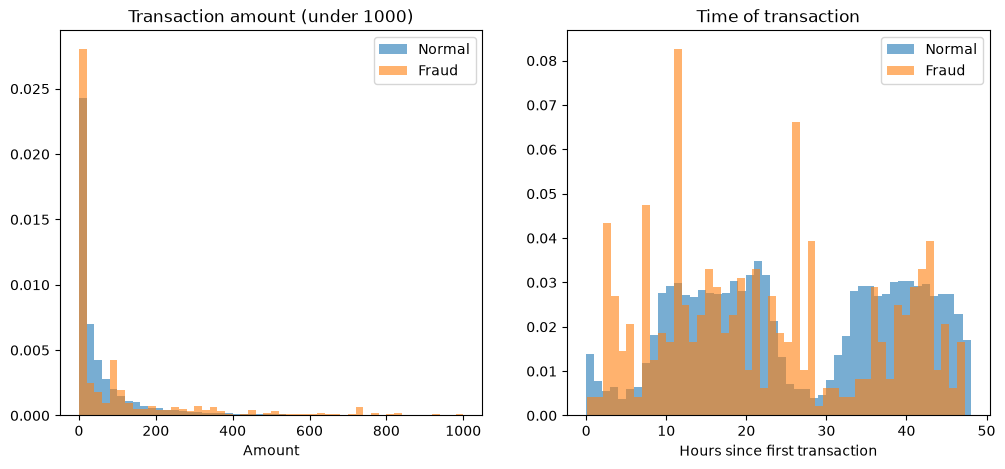

In [8]:
# compare Amount and Time for normal and fraud transactions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(df[df['Class'] == 0]['Amount'], bins=50, alpha=0.6, density=True, label='Normal', range=(0, 1000))
axes[0].hist(df[df['Class'] == 1]['Amount'], bins=50, alpha=0.6, density=True, label='Fraud', range=(0, 1000))
axes[0].set_title('Transaction amount (under 1000)')
axes[0].set_xlabel('Amount')
axes[0].legend()

axes[1].hist(df[df['Class'] == 0]['Time'] / 3600, bins=48, alpha=0.6, density=True, label='Normal')
axes[1].hist(df[df['Class'] == 1]['Time'] / 3600, bins=48, alpha=0.6, density=True, label='Fraud')
axes[1].set_title('Time of transaction')
axes[1].set_xlabel('Hours since first transaction')
axes[1].legend()

plt.show()

In [9]:
print(df[['Time', 'Amount']].describe())

                Time         Amount
count  284807.000000  284807.000000
mean    94813.859575      88.349619
std     47488.145955     250.120109
min         0.000000       0.000000
25%     54201.500000       5.600000
50%     84692.000000      22.000000
75%    139320.500000      77.165000
max    172792.000000   25691.160000


### Split and scale

`V1` to `V28` are already scaled by the PCA, but `Time` and `Amount` are not (Amount goes up to about 25,000).
I split first (60% train, 20% validation, 20% test, stratified so every split keeps the same fraud rate) and then fit the scaler on the training set only, so no information from the validation or test sets leaks in.

In [10]:
X = df.drop('Class', axis=1)
y = df['Class']

# 60 / 20 / 20 split, stratified on the class
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=SEED)

print("Train:", X_train.shape, "fraud:", y_train.sum())
print("Val:  ", X_val.shape, "fraud:", y_val.sum())
print("Test: ", X_test.shape, "fraud:", y_test.sum())

Train: (170884, 30) fraud: 295
Val:   (56961, 30) fraud: 98
Test:  (56962, 30) fraud: 99


In [11]:
# scale Time and Amount, fitted on the training set only
scaler = StandardScaler()
X_train[['Time', 'Amount']] = scaler.fit_transform(X_train[['Time', 'Amount']])
X_val[['Time', 'Amount']] = scaler.transform(X_val[['Time', 'Amount']])
X_test[['Time', 'Amount']] = scaler.transform(X_test[['Time', 'Amount']])

X_train = X_train.values.astype('float32')
X_val = X_val.values.astype('float32')
X_test = X_test.values.astype('float32')
y_train = y_train.values
y_val = y_val.values
y_test = y_test.values

## Models

1. Logistic regression as a simple baseline.
2. A small dense network (32, 16, 1), the same shape as the predictor in my Adaptive-Alpha project, trained plainly.
3. The same network trained with class weights, so each fraud example counts for much more in the loss.

In [12]:
# 1. logistic regression baseline
log_reg = LogisticRegression(max_iter=1000, random_state=SEED)
log_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [13]:
def build_model(input_dim):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(input_dim,)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
                  loss='binary_crossentropy',
                  metrics=[tf.keras.metrics.AUC(curve='PR', name='pr_auc')])
    return model

EPOCHS = 30
BATCH_SIZE = 256

# stop when validation PR-AUC stops improving and keep the best weights
def early_stop():
    return tf.keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=5,
                                            restore_best_weights=True)

In [14]:
# 2. plain network, no class weights
tf.keras.utils.set_random_seed(SEED)
plain_model = build_model(X_train.shape[1])
plain_model.summary()

plain_history = plain_model.fit(X_train, y_train,
                                validation_data=(X_val, y_val),
                                epochs=EPOCHS, batch_size=BATCH_SIZE,
                                callbacks=[early_stop()], verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


668/668 - 1s - 2ms/step - loss: 0.0349 - pr_auc: 0.3450 - val_loss: 0.0047 - val_pr_auc: 0.6266


Epoch 2/30


668/668 - 1s - 888us/step - loss: 0.0034 - pr_auc: 0.7621 - val_loss: 0.0038 - val_pr_auc: 0.7200


Epoch 3/30


668/668 - 1s - 757us/step - loss: 0.0029 - pr_auc: 0.8130 - val_loss: 0.0036 - val_pr_auc: 0.7519


Epoch 4/30


668/668 - 1s - 758us/step - loss: 0.0027 - pr_auc: 0.8329 - val_loss: 0.0036 - val_pr_auc: 0.7687


Epoch 5/30


668/668 - 0s - 675us/step - loss: 0.0025 - pr_auc: 0.8443 - val_loss: 0.0035 - val_pr_auc: 0.7739


Epoch 6/30


668/668 - 1s - 749us/step - loss: 0.0024 - pr_auc: 0.8550 - val_loss: 0.0035 - val_pr_auc: 0.7736


Epoch 7/30


668/668 - 1s - 785us/step - loss: 0.0023 - pr_auc: 0.8620 - val_loss: 0.0034 - val_pr_auc: 0.7746


Epoch 8/30


668/668 - 1s - 847us/step - loss: 0.0022 - pr_auc: 0.8698 - val_loss: 0.0034 - val_pr_auc: 0.7818


Epoch 9/30


668/668 - 0s - 742us/step - loss: 0.0021 - pr_auc: 0.8782 - val_loss: 0.0034 - val_pr_auc: 0.7809


Epoch 10/30


668/668 - 1s - 771us/step - loss: 0.0020 - pr_auc: 0.8872 - val_loss: 0.0035 - val_pr_auc: 0.7859


Epoch 11/30


668/668 - 1s - 750us/step - loss: 0.0020 - pr_auc: 0.8895 - val_loss: 0.0034 - val_pr_auc: 0.7866


Epoch 12/30


668/668 - 0s - 744us/step - loss: 0.0019 - pr_auc: 0.8963 - val_loss: 0.0035 - val_pr_auc: 0.7862


Epoch 13/30


668/668 - 1s - 876us/step - loss: 0.0018 - pr_auc: 0.8980 - val_loss: 0.0034 - val_pr_auc: 0.7899


Epoch 14/30


668/668 - 0s - 709us/step - loss: 0.0017 - pr_auc: 0.9051 - val_loss: 0.0035 - val_pr_auc: 0.7895


Epoch 15/30


668/668 - 0s - 682us/step - loss: 0.0017 - pr_auc: 0.9102 - val_loss: 0.0034 - val_pr_auc: 0.7890


Epoch 16/30


668/668 - 0s - 744us/step - loss: 0.0016 - pr_auc: 0.9141 - val_loss: 0.0035 - val_pr_auc: 0.7914


Epoch 17/30


668/668 - 0s - 735us/step - loss: 0.0016 - pr_auc: 0.9172 - val_loss: 0.0035 - val_pr_auc: 0.7905


Epoch 18/30


668/668 - 1s - 761us/step - loss: 0.0015 - pr_auc: 0.9183 - val_loss: 0.0036 - val_pr_auc: 0.7941


Epoch 19/30


668/668 - 1s - 867us/step - loss: 0.0015 - pr_auc: 0.9259 - val_loss: 0.0036 - val_pr_auc: 0.7933


Epoch 20/30


668/668 - 1s - 802us/step - loss: 0.0014 - pr_auc: 0.9281 - val_loss: 0.0037 - val_pr_auc: 0.7928


Epoch 21/30


668/668 - 1s - 766us/step - loss: 0.0014 - pr_auc: 0.9327 - val_loss: 0.0037 - val_pr_auc: 0.7956


Epoch 22/30


668/668 - 1s - 749us/step - loss: 0.0013 - pr_auc: 0.9352 - val_loss: 0.0038 - val_pr_auc: 0.7929


Epoch 23/30


668/668 - 0s - 724us/step - loss: 0.0013 - pr_auc: 0.9387 - val_loss: 0.0038 - val_pr_auc: 0.7940


Epoch 24/30


668/668 - 0s - 688us/step - loss: 0.0012 - pr_auc: 0.9416 - val_loss: 0.0040 - val_pr_auc: 0.7840


Epoch 25/30


668/668 - 1s - 862us/step - loss: 0.0012 - pr_auc: 0.9442 - val_loss: 0.0040 - val_pr_auc: 0.7783


Epoch 26/30


668/668 - 1s - 757us/step - loss: 0.0012 - pr_auc: 0.9452 - val_loss: 0.0042 - val_pr_auc: 0.7637


In [15]:
# class weights: each class gets the same total weight
n_normal = (y_train == 0).sum()
n_fraud = (y_train == 1).sum()
class_weight = {0: len(y_train) / (2 * n_normal),
                1: len(y_train) / (2 * n_fraud)}
print(class_weight)

{0: np.float64(0.5008646512963908), 1: np.float64(289.63389830508476)}


In [16]:
# 3. same network with class weights
tf.keras.utils.set_random_seed(SEED)
weighted_model = build_model(X_train.shape[1])

weighted_history = weighted_model.fit(X_train, y_train,
                                      validation_data=(X_val, y_val),
                                      epochs=EPOCHS, batch_size=BATCH_SIZE,
                                      class_weight=class_weight, callbacks=[early_stop()], verbose=2)

Epoch 1/30


668/668 - 1s - 2ms/step - loss: 0.3177 - pr_auc: 0.6364 - val_loss: 0.1422 - val_pr_auc: 0.6412


Epoch 2/30


668/668 - 1s - 809us/step - loss: 0.1564 - pr_auc: 0.7574 - val_loss: 0.1124 - val_pr_auc: 0.6692


Epoch 3/30


668/668 - 1s - 914us/step - loss: 0.1302 - pr_auc: 0.7505 - val_loss: 0.1025 - val_pr_auc: 0.6524


Epoch 4/30


668/668 - 1s - 874us/step - loss: 0.1126 - pr_auc: 0.7391 - val_loss: 0.0932 - val_pr_auc: 0.6470


Epoch 5/30


668/668 - 0s - 745us/step - loss: 0.0983 - pr_auc: 0.7338 - val_loss: 0.0842 - val_pr_auc: 0.6529


Epoch 6/30


668/668 - 0s - 721us/step - loss: 0.0887 - pr_auc: 0.7243 - val_loss: 0.0764 - val_pr_auc: 0.6405


Epoch 7/30


668/668 - 1s - 762us/step - loss: 0.0798 - pr_auc: 0.7353 - val_loss: 0.0703 - val_pr_auc: 0.6483


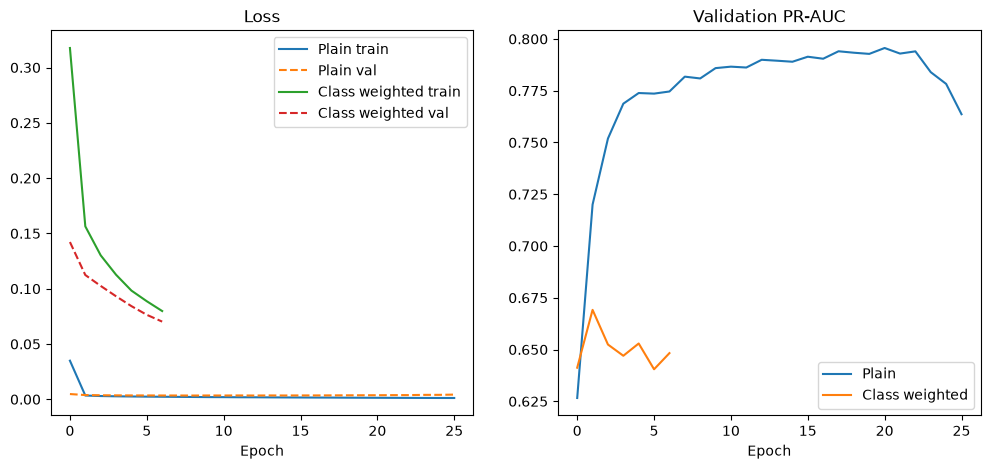

In [17]:
# training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name, hist in [('Plain', plain_history), ('Class weighted', weighted_history)]:
    axes[0].plot(hist.history['loss'], label=name + ' train')
    axes[0].plot(hist.history['val_loss'], '--', label=name + ' val')
    axes[1].plot(hist.history['val_pr_auc'], label=name)

axes[0].set_title('Loss')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[1].set_title('Validation PR-AUC')
axes[1].set_xlabel('Epoch')
axes[1].legend()
plt.show()

The weighted model's loss is not directly comparable with the plain one, because the weights change what the loss measures. PR-AUC on the validation set is the fairer comparison.

## Choosing a decision threshold

Every model outputs a probability, and 0.5 is just the default cut-off. For each model I pick the threshold that gives the best F1 on the **validation** set, so the test set is only used once at the very end.

In [18]:
# predicted fraud probabilities
val_probs = {
    'Logistic regression': log_reg.predict_proba(X_val)[:, 1],
    'Dense network': plain_model.predict(X_val, verbose=0).reshape(-1),
    'Dense network + class weights': weighted_model.predict(X_val, verbose=0).reshape(-1)
}
test_probs = {
    'Logistic regression': log_reg.predict_proba(X_test)[:, 1],
    'Dense network': plain_model.predict(X_test, verbose=0).reshape(-1),
    'Dense network + class weights': weighted_model.predict(X_test, verbose=0).reshape(-1)
}

In [19]:
def best_threshold(y_true, probs):
    precision, recall, thresholds = precision_recall_curve(y_true, probs)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    # the last precision/recall pair has no threshold
    i = np.argmax(f1[:-1])
    return thresholds[i], f1[i]

thresholds = {}
for name, probs in val_probs.items():
    t, f1 = best_threshold(y_val, probs)
    thresholds[name] = t
    print(f"{name}: best threshold = {t:.4f}, validation F1 = {f1:.3f}")

Logistic regression: best threshold = 0.1003, validation F1 = 0.745
Dense network: best threshold = 0.6274, validation F1 = 0.802
Dense network + class weights: best threshold = 0.9774, validation F1 = 0.759


## Test set results

In [20]:
def evaluate(y_true, probs, threshold):
    preds = (probs >= threshold).astype(int)
    return {
        'Threshold': round(float(threshold), 4),
        'Accuracy': accuracy_score(y_true, preds),
        'Precision': precision_score(y_true, preds, zero_division=0),
        'Recall': recall_score(y_true, preds),
        'F1': f1_score(y_true, preds),
        'PR-AUC': average_precision_score(y_true, probs)
    }

rows = []
for name, probs in test_probs.items():
    rows.append({'Model': name, **evaluate(y_test, probs, 0.5)})
    rows.append({'Model': name + ' (tuned)', **evaluate(y_test, probs, thresholds[name])})

results = pd.DataFrame(rows).set_index('Model')
results.round(4)

,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
Model,,,,,,
Logistic regression,0.5000,0.9993,0.8701,0.6768,0.7614,0.7755
Logistic regression (tuned),0.1003,0.9992,0.7647,0.7879,0.7761,0.7755
Dense network,0.5000,0.9996,0.9405,0.7980,0.8634,0.8593
Dense network (tuned),0.6274,0.9995,0.9390,0.7778,0.8508,0.8593
Dense network + class weights,0.5000,0.9817,0.0795,0.8990,0.1461,0.7184
Dense network + class weights (tuned),0.9774,0.9994,0.8495,0.7980,0.8229,0.7184


Accuracy is above 98% for every row, even though recall and precision change a lot between them. This is the same point as the "always normal" check earlier: with this little fraud, accuracy cannot tell the models apart. PR-AUC does not depend on the threshold, so it is the same for the default and tuned versions of each model.

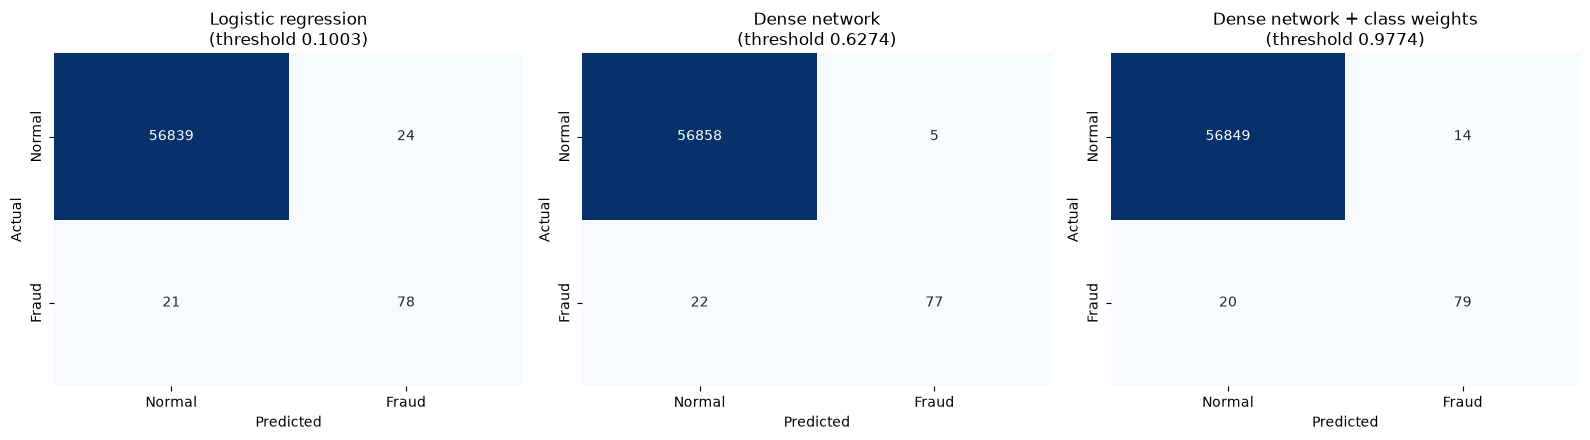

In [21]:
# confusion matrices on the test set at the tuned thresholds
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (name, probs) in zip(axes, test_probs.items()):
    preds = (probs >= thresholds[name]).astype(int)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal', 'Fraud'], yticklabels=['Normal', 'Fraud'])
    ax.set_title(f"{name}\n(threshold {thresholds[name]:.4f})")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

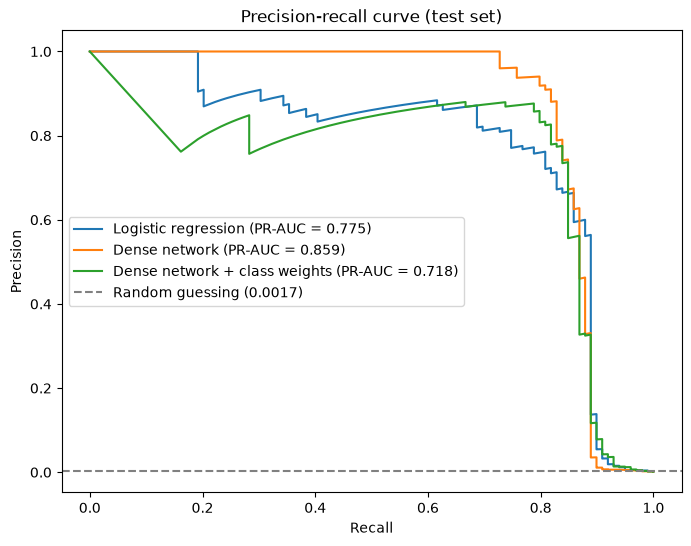

In [22]:
# precision-recall curves on the test set
plt.figure(figsize=(8, 6))

for name, probs in test_probs.items():
    precision, recall, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    plt.plot(recall, precision, label=f"{name} (PR-AUC = {ap:.3f})")

baseline = y_test.mean()
plt.axhline(baseline, color='grey', linestyle='--', label=f"Random guessing ({baseline:.4f})")
plt.title('Precision-recall curve (test set)')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.legend()
plt.savefig('pr_curve.png', dpi=100, bbox_inches='tight')
plt.show()

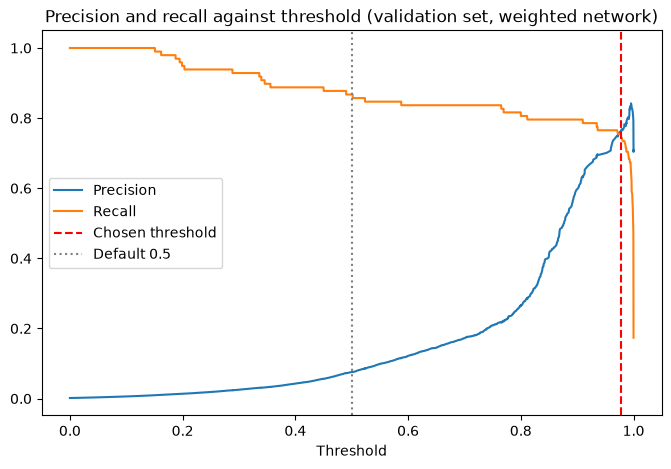

In [23]:
# how precision and recall change with the threshold for the weighted network
name = 'Dense network + class weights'
precision, recall, thr = precision_recall_curve(y_val, val_probs[name])

plt.figure(figsize=(8, 5))
plt.plot(thr, precision[:-1], label='Precision')
plt.plot(thr, recall[:-1], label='Recall')
plt.axvline(thresholds[name], color='red', linestyle='--', label='Chosen threshold')
plt.axvline(0.5, color='grey', linestyle=':', label='Default 0.5')
plt.title('Precision and recall against threshold (validation set, weighted network)')
plt.xlabel('Threshold')
plt.legend()
plt.show()

## Conclusion

- Every model scores above 98% accuracy on the test set, and the "always normal" guess scores 99.8%, so accuracy is useless for comparing them. The class-weighted network at the default 0.5 threshold still gets 98.2% accuracy while only about 8% of the transactions it flags are actually fraud.
- The plain dense network was the best model overall, with a test PR-AUC of 0.859 against 0.776 for logistic regression. At the default threshold it caught 79.8% of the test fraud with 94.1% precision (F1 0.863).
- Class weights did what they are meant to do at 0.5: recall went up to 89.9%, but precision fell to 7.95% because the model now flags over a thousand normal transactions. Its PR-AUC (0.718) was lower than the plain network, and validation PR-AUC was best after only 2 epochs, so with a weight of about 290 on each fraud example it overfits the few fraud cases very quickly.
- Tuning the threshold on the validation set mattered most for the weighted network (F1 went from 0.146 to 0.823 with a threshold of 0.977) and helped logistic regression a little. For the plain network the tuned threshold of 0.627 was slightly worse on the test set than 0.5 (F1 0.851 against 0.863). With only 98 fraud cases in the validation set, the "best" threshold is noisy.
- Which threshold to use in practice depends on the cost of a missed fraud against the cost of annoying a customer with a false alarm, which this dataset does not tell us.